# Bài kiểm tra 3 · Tối ưu và so sánh cải tiến

Không giả định cải tiến bắt buộc tốt hơn. Khóa lựa chọn bằng CV trước khi chấm test. Xem `selection_frozen_before_test.json` và hash trong `results.json`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import Image, display
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
DATA=ROOT/'reports/experiments'
assert (DATA/'results.json').exists(), 'Chạy python -m src.experiments trước'
result=json.loads((DATA/'results.json').read_text(encoding='utf-8'))
def table(name): return pd.read_csv(DATA/name)
def figure(name): display(Image(filename=str(ROOT/'reports/figures'/name)))


## 1 Hạn chế ban đầu và giải pháp

Đa cộng tuyến và khoảng cách train–CV dẫn đến tìm alpha. Đuôi diện tích và lỗi nhóm giá cao dẫn đến so sánh clipping/log. Quan hệ phi tuyến dẫn đến thử boosting. Thêm tuổi nhà, tổng diện tích, tổng số phòng tắm và cờ tiện ích để kiểm tra tín hiệu tổng hợp; không coi đó là cải tiến đã có hiệu quả trước khi đo.

In [2]:
from src.modeling import FeatureBuilder
from src.preprocessing import load_raw
raw=load_raw(ROOT/'data/raw/AmesHousing.tsv')
train=raw[raw['Yr Sold']<2010].reset_index(drop=True)
display(FeatureBuilder(engineered=True).fit_transform(train).filter(items=['HouseAge','RemodAge','TotalSF','TotalBath','HasGarage','HasBasement','TotalPorch']).head())

,HouseAge,RemodAge,TotalSF,TotalBath,HasGarage,HasBasement,TotalPorch
0,53.0,53.0,1764.0,1.0,1,1,0
1,35.0,35.0,2868.0,3.0,1,1,21
2,37.0,14.0,4656.0,3.5,1,1,111
3,12.0,12.0,2553.0,2.5,1,1,30
4,6.0,6.0,3291.0,2.5,1,1,46


## 2 Ablation cùng alpha Ridge

Alpha Ridge được chọn trên cấu hình gốc, sau đó giữ nguyên alpha khi đo lần lượt thêm đặc trưng, bỏ clipping và log diện tích. Các dòng dùng cùng fold, nhãn và chỉ số. Đây là tác động của thay đổi trong cấu hình alpha cố định, không phải bằng chứng mọi khả năng feature engineering đều không hiệu quả.

,model,cv_rmse_log_mean,cv_rmse_log_std,cv_train_rmse_log_mean,cv_mae_usd_mean,cv_rmse_usd_mean,cv_r2_usd_mean,fit_seconds_mean,engineered,clipping,log_areas,alpha
0,Ablation_Original_clip,0.127720,0.007501,0.088760,14576.518516,26988.481159,0.881015,0.237324,False,True,False,10.0
1,Ablation_Features_clip,0.129821,0.008337,0.087815,14641.430481,29158.670110,0.859051,0.257401,True,True,False,10.0
2,Ablation_Features_no_clip,0.152611,0.027517,0.091716,17321.146377,74735.744107,-0.126352,0.217922,True,False,False,10.0
3,Ablation_Features_log_no_clip,0.129715,0.010539,0.087568,14690.695955,30412.918611,0.845576,0.234258,True,False,True,10.0


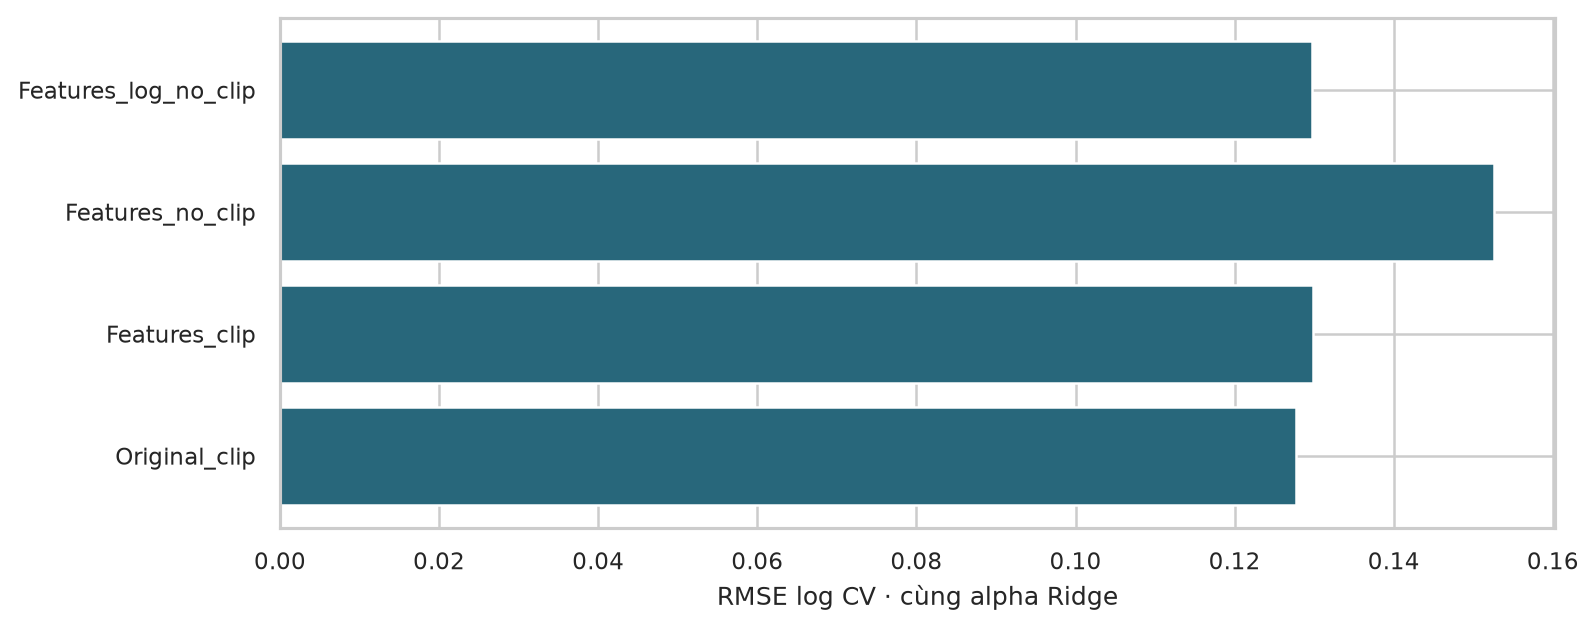

In [3]:
display(table('ablation.csv'))
figure('12_ablation.png')

Các biến tổng hợp chưa giảm RMSE log; bỏ clipping làm kết quả kém ổn định hơn. Log diện tích phục hồi phần lớn chất lượng so với không clip, nhưng vẫn chưa vượt cấu hình gốc. Giữ cấu hình gốc theo CV, không sửa quyết định dựa trên test.

## 3 Tìm kiếm siêu tham số

GridSearchCV fit lại toàn bộ pipeline theo fold năm. Ridge tìm alpha 0.1–1000; Lasso 0.0001–0.03; Elastic Net kết hợp alpha và l1_ratio; HistGradientBoosting thử số lá tối đa và phạt L2, early_stopping=False để không trộn một tập kiểm định ngẫu nhiên vào quy trình thời gian.

{
  "Ridge_tuned": {
    "alpha": 10.0
  },
  "Lasso_tuned": {
    "alpha": 0.0003
  },
  "ElasticNet_tuned": {
    "alpha": 0.0003,
    "l1_ratio": 0.9
  },
  "HistGradientBoosting": {
    "l2_regularization": 10.0,
    "max_leaf_nodes": 15
  }
}


,model,cv_rmse_log_mean,cv_rmse_log_std,cv_train_rmse_log_mean,cv_mae_usd_mean,cv_rmse_usd_mean,cv_r2_usd_mean,fit_seconds_mean
0,Ridge_tuned,0.127720,0.007501,0.088760,14576.518516,26988.481159,0.881015,0.228740
1,Lasso_tuned,0.127188,0.009769,0.087586,14447.917366,26471.060950,0.885324,0.274352
2,ElasticNet_tuned,0.127305,0.009797,0.086843,14472.739184,26501.349220,0.885064,0.340136
3,HistGradientBoosting,0.129835,0.005374,0.060945,15440.170039,26239.553513,0.889655,3.536636


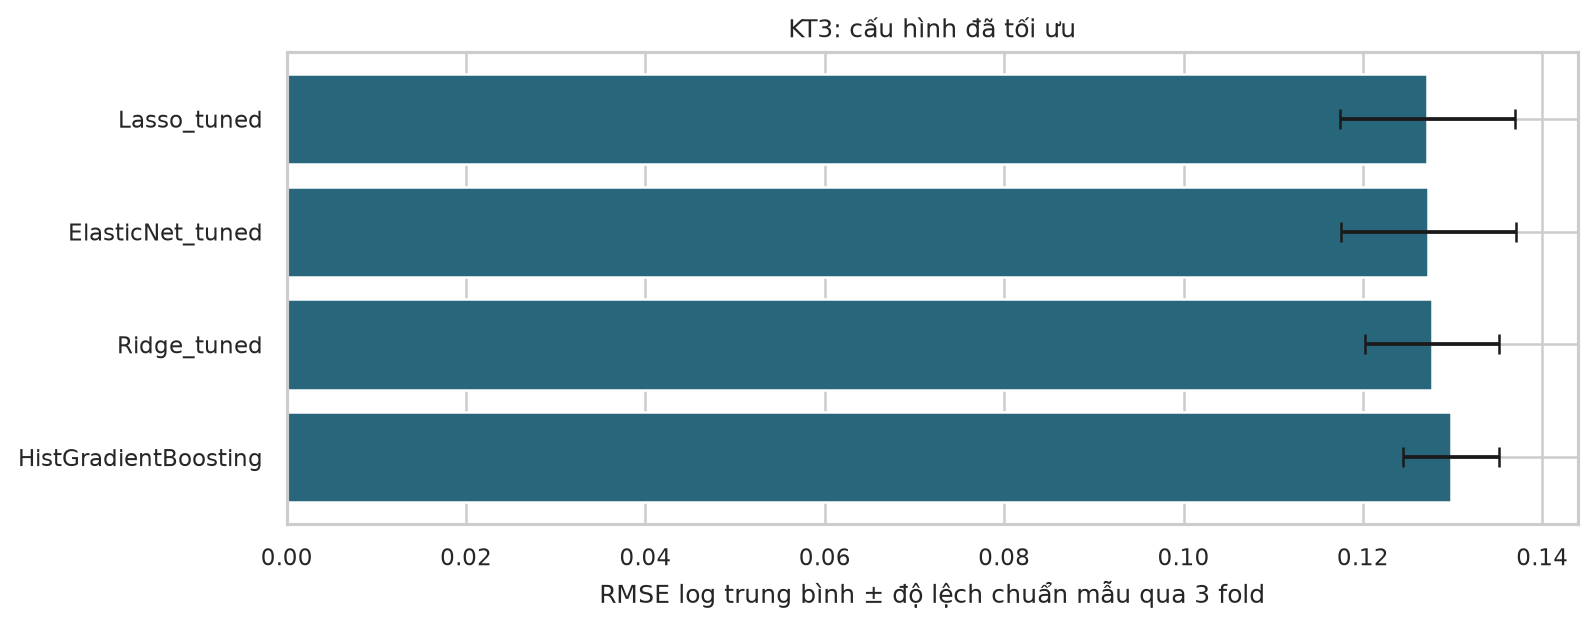

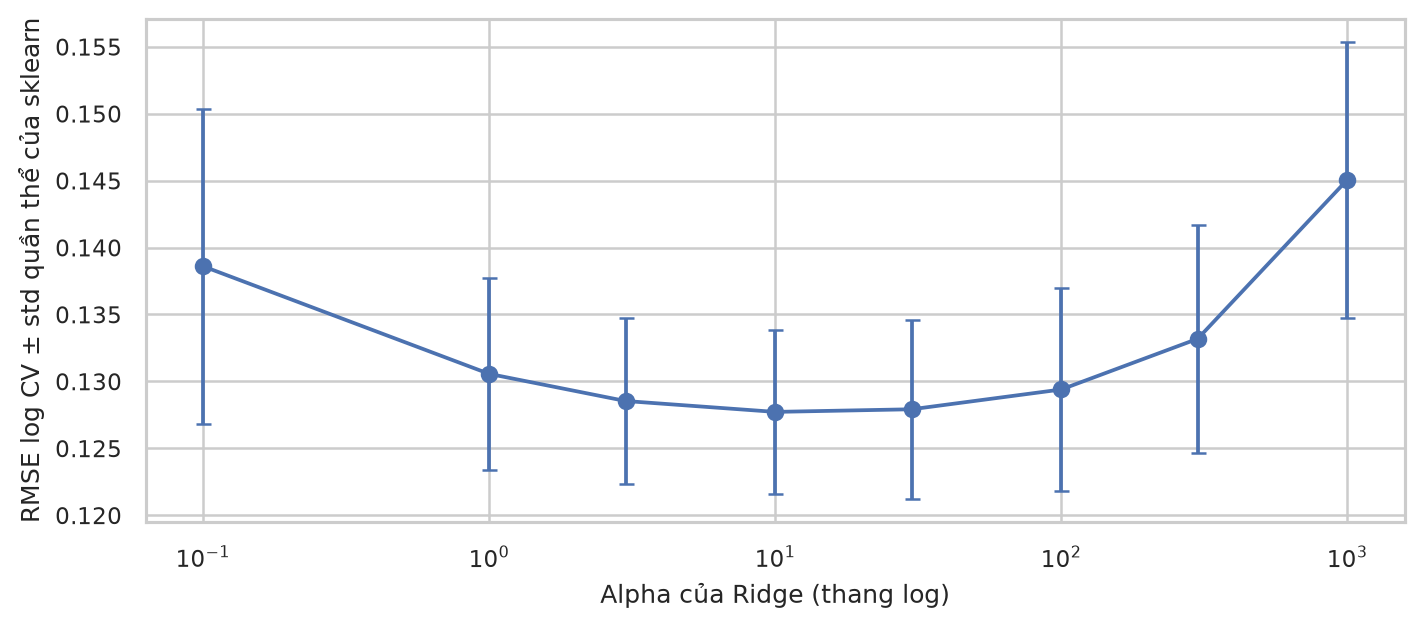

In [4]:
print(json.dumps(result['best_params'],indent=2))
display(table('kt3_cv_summary.csv'))
figure('10_kt3_cv.png')
figure('13_alpha_validation.png')

## 4 RidgeCV và LassoCV không rò rỉ preprocessing

Ví dụ bổ sung đóng băng imputer/scaler/encoder bằng dữ liệu năm 2006 trước mọi validation. Do đó, các lớp RidgeCV/LassoCV không nhìn thống kê tương lai. Đây là thí nghiệm khác preprocessing với bảng chính; không dùng để khẳng định khác biệt chỉ do thuật toán CV. Bảng chính vẫn dùng refit toàn pipeline trong mỗi fold.

In [5]:
print((DATA/'ridgecv_lassocv.json').read_text(encoding='utf-8'))

{
  "preprocessing_fit_year": 2006,
  "calibration_rows": 625,
  "ridgecv_alpha": 30.0,
  "lassocv_alpha": 0.0003,
  "note": "Minh họa đúng lớp RidgeCV/LassoCV với preprocessing đóng băng năm 2006; không thay thế CV refit pipeline chính."
}


## 5 Độ thưa và giải thích mô hình

Lasso tạo nhiều hệ số 0 hơn Ridge. Hệ số sau chuẩn hóa không phải tác động nhân quả và độ lớn số so với biến one-hot chưa scale không hoàn toàn tương đương. Dùng permutation importance trên validation 2009 để bổ sung bằng chứng.

,model,coefficients,nonzero
0,Ridge_tuned,350,349
1,Lasso_tuned,350,148
2,ElasticNet_tuned,350,158


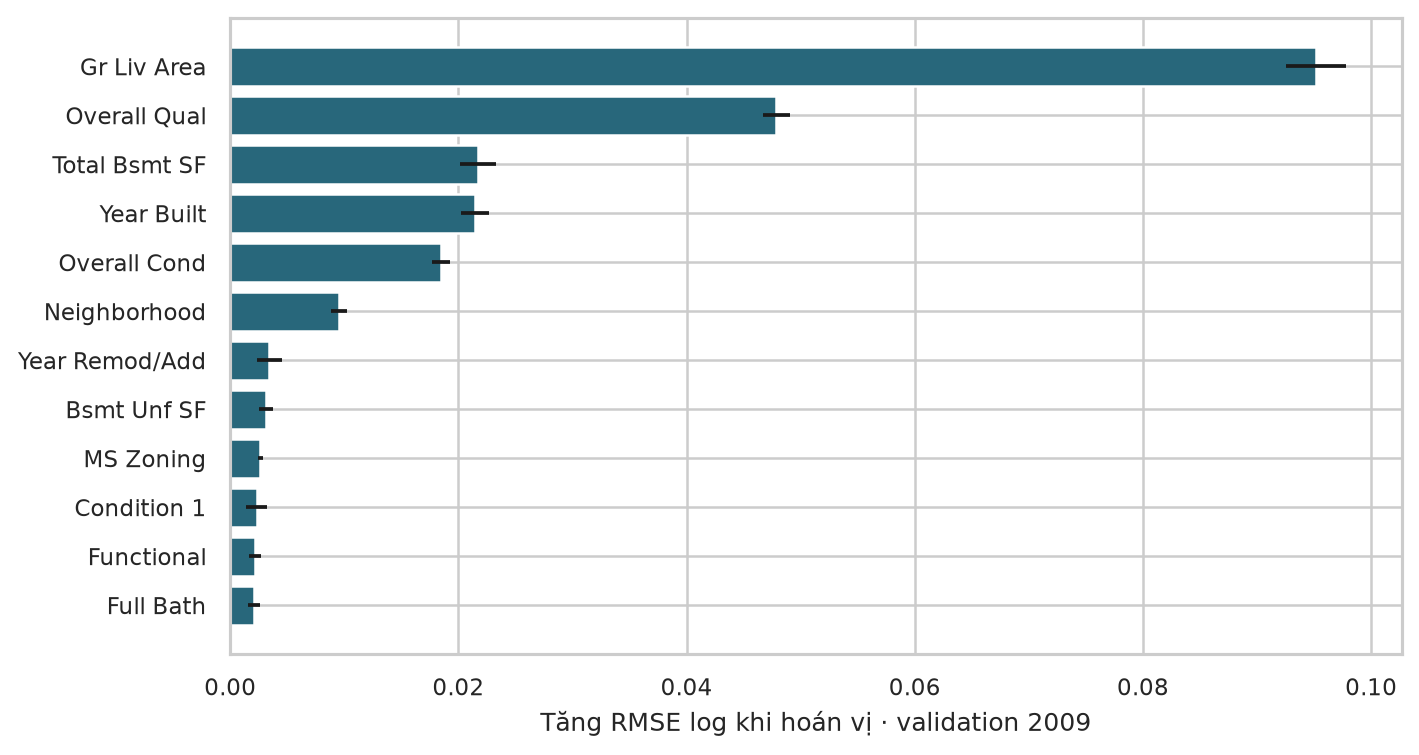

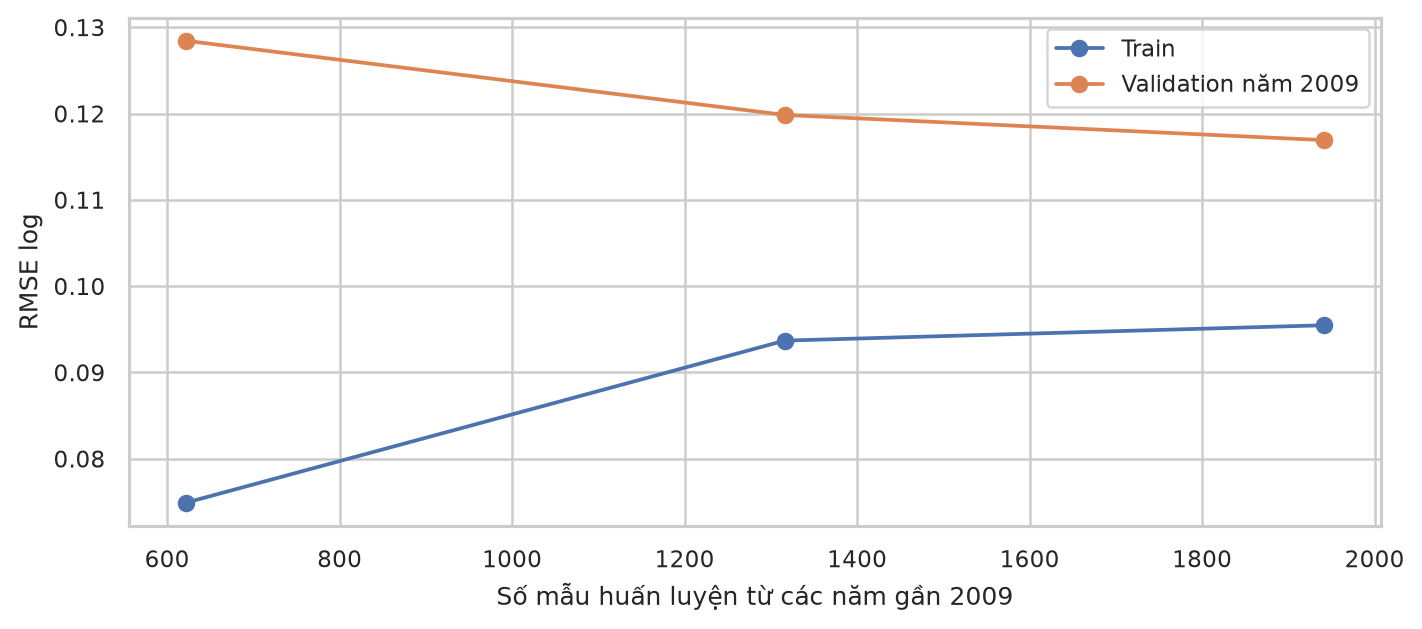

In [6]:
display(table('sparsity.csv'))
figure('15_permutation_importance.png')
figure('14_learning_curve.png')

Khi tăng dữ liệu quá khứ trước validation 2009, sai số validation giảm; đường train và validation tiến gần hơn. Kết quả chỉ có ba kích thước và cùng một năm validation, không phải bảo đảm cho mọi thời kỳ. Diện tích ở, chất lượng, tầng hầm và năm xây dựng có vai trò lớn theo phép hoán vị, nhưng đặc trưng tương quan có thể chia sẻ tầm quan trọng.

## 6 Lựa chọn cuối và đánh giá test

Lasso alpha=0.0003 thắng theo CV và được giữ nguyên. Một số cấu hình khác có test RMSE log thấp hơn đôi chút; không chọn lại vì điều đó sẽ biến test thành tập chọn mô hình. Mức cải thiện so với cấu hình KT2 tốt nhất nhỏ hơn độ lệch chuẩn giữa fold, nên không tuyên bố ưu thế thống kê chắc chắn.

Selected: Lasso_tuned
CV: {'model': 'Lasso_tuned', 'cv_rmse_log_mean': 0.12718794218082302, 'cv_rmse_log_std': 0.00976949988672381, 'cv_train_rmse_log_mean': 0.08758552129769846, 'cv_mae_usd_mean': 14447.917365988482, 'cv_rmse_usd_mean': 26471.060950495652, 'cv_r2_usd_mean': 0.8853241898663354, 'fit_seconds_mean': 0.27435186665388756}
Test: {'fit_full_seconds': 0.562137700006133, 'train_rmse_log': 0.10182563673260081, 'train_mae_usd': 12267.782915786773, 'train_rmse_usd': 19493.77684681068, 'train_r2_usd': 0.9413433578445113, 'rmse_log': 0.15095392456295836, 'mae_usd': 14840.276898088196, 'rmse_usd': 21218.728642400758, 'r2_usd': 0.918928046455907}


,model,cv_rmse_log_mean,cv_rmse_log_std,cv_train_rmse_log_mean,cv_mae_usd_mean,cv_rmse_usd_mean,cv_r2_usd_mean,fit_seconds_mean,rmse_log
0,DummyMeanLog,0.404647,0.011984,0.405639,56380.639767,80913.520270,-0.032778,0.246781,0.417947
1,LinearRegression,0.143351,0.017889,0.077947,16219.925676,32253.421848,0.823780,0.236684,0.171491
2,Ridge_default,0.127720,0.007501,0.088760,14576.518516,26988.481159,0.881015,0.227575,0.149412
3,Lasso_default,0.128952,0.009852,0.100333,14600.584869,27315.771810,0.877522,0.263735,0.151697
4,ElasticNet_default,0.127485,0.009612,0.093600,14457.973176,26738.356067,0.882911,0.278732,0.149169
5,Ridge_tuned,0.127720,0.007501,0.088760,14576.518516,26988.481159,0.881015,0.228740,0.149412
6,Lasso_tuned,0.127188,0.009769,0.087586,14447.917366,26471.060950,0.885324,0.274352,0.150954
7,ElasticNet_tuned,0.127305,0.009797,0.086843,14472.739184,26501.349220,0.885064,0.340136,0.151252
8,HistGradientBoosting,0.129835,0.005374,0.060945,15440.170039,26239.553513,0.889655,3.536636,0.155017


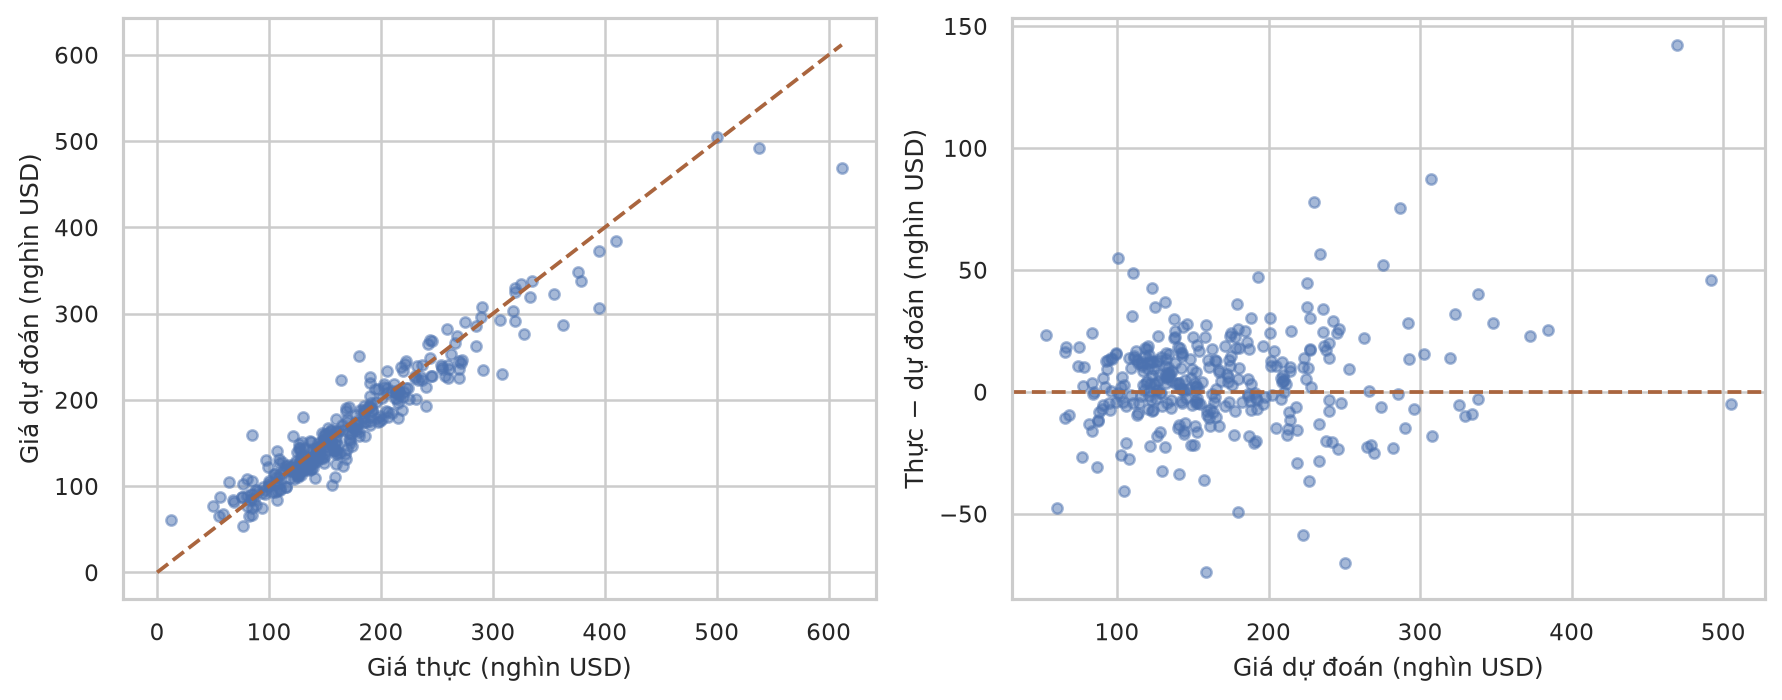

In [7]:
print('Selected:',result['selected_model'])
print('CV:',result['selected_cv'])
print('Test:',result['test_metrics'])
display(table('cv_vs_test.csv'))
figure('11_predictions_residuals.png')

## 7 Thực hành và hạn chế

Xem ô thực hành của KT2 để đổi alpha trong train fold. Xem `src/experiments.py` để đổi lưới và chạy lại một phiên bản thực nghiệm, không tuyên bố test mới độc lập sau khi đã nhìn nhiều phiên bản. Giới hạn: ba năm validation, test 2010 một phần năm, miền Ames lịch sử, cấu hình cải tiến hữu hạn và CV có độ lạc quan do tìm kiếm. Phần cá nhân và lịch sử đóng góp cần sinh viên bổ sung thật.